# Sentinel-1: read VV and VH radar imagery at Harvard Forest

**Worked demo.** Sentinel-1A imaged Prospect Hill, Massachusetts, on June 5, 2023, the same day as the field visit in the Harvard Forest LAI lab. Radar sends out microwave pulses and measures the returning signal. These images show backscatter, not color or sunlight reflected from leaves.

A Level-1 Ground Range Detected (GRD) product contains detected radar magnitude; it does not retain the complex phase. The radiometrically terrain-corrected **RTC** product here is derived from GRD. It is calibrated and terrain corrected, including a correction for the effect of slope on the illuminated area. Missing data, radar shadows, and layover are not recovered by that correction.

| Raster | Transmit → receive | What it measures |
|---|---|---|
| VV | Vertical → vertical | Co-polarized return. Roughness, moisture, and viewing geometry all affect it. |
| VH | Vertical → horizontal | Cross-polarized return. Branches and other canopy structures can change the polarization; VH is often weaker than VV. |

There are no HH or HV rasters in this acquisition.

In [1]:
%pip -q install rasterio

Note: you may need to restart the kernel to use updated packages.


## Download the sample

The Vision ZIP holds cropped, georeferenced VV and VH GeoTIFFs and `provenance.json`, which identifies the full radar scene and lists the source asset URLs.

In [2]:
%%bash
set -e
wget -nv -O sentinel-1-rtc-demo.zip https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-1-rtc-demo.zip
unzip -oq sentinel-1-rtc-demo.zip -d sentinel-1-rtc-demo

2026-11-18 12:43:32 URL:https://vision.csi.miamioh.edu/data/cse620b/forestry/sentinel-1-rtc-demo.zip

 [103381/103381] -> "sentinel-1-rtc-demo.zip" [1]


In [3]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

## Read a small window from each raster

Rasterio reads band 1 of each already-cropped GeoTIFF over the same 1.2 km square in UTM zone 18N. `masked=True` preserves the raster's nodata mask. The arrays contain **linear backscatter power**. We use those linear values for the VV/VH ratio and convert positive values to decibels for the side-by-side display.

In [4]:
power = {}
for polarization in ("vv", "vh"):
    with rasterio.open(f"sentinel-1-rtc-demo/{polarization}.tif") as src:
        values = src.read(1, masked=True)
        power[polarization] = np.ma.masked_less_equal(np.ma.masked_invalid(values), 0)
        print(f"{polarization.upper()}: {src.crs}, {src.res} m, crop {values.shape}")

VV: EPSG:32618, (10.0, 10.0) m, crop (120, 120)
VH: EPSG:32618, (10.0, 10.0) m, crop (120, 120)


## Compare the channels on the same display scale

Plotting both bands on the same dB scale lets you see which return is stronger. The conversion is `10 × log10(power)`: for example, a linear power of 0.01 is −20 dB. The granular texture is partly **speckle**, caused by interference among returns within a pixel. The ratio panel uses linear power: a ratio above 1 means VV is stronger than VH. It is not a direct measurement of leaf area.

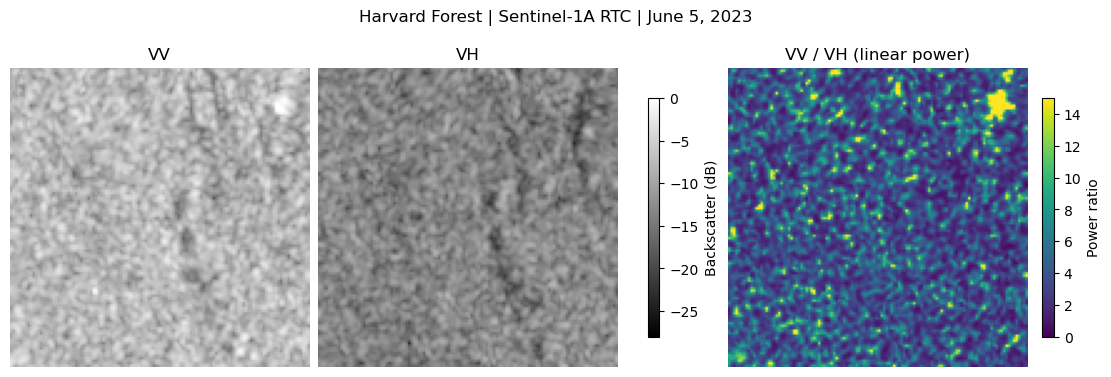

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), layout="constrained")
for ax, polarization in zip(axes[:2], ("vv", "vh")):
    decibels = 10 * np.ma.log10(power[polarization])
    image = ax.imshow(decibels, cmap="gray", vmin=-28, vmax=0)
    ax.set_title(polarization.upper())
fig.colorbar(image, ax=axes[:2], shrink=0.65, label="Backscatter (dB)")

ratio = power["vv"] / power["vh"]
image = axes[2].imshow(ratio, cmap="viridis", vmin=0, vmax=15)
axes[2].set_title("VV / VH (linear power)")
fig.colorbar(image, ax=axes[2], shrink=0.65, label="Power ratio")
for ax in axes:
    ax.set_axis_off()
fig.suptitle("Harvard Forest | Sentinel-1A RTC | June 5, 2023")
plt.show()

## Where to get more imagery

In the [ASF Vertex search portal](https://search.asf.alaska.edu/), draw an area of interest, set the dates, and choose **OPERA RTC-S1** for another terrain-corrected product. Pick a dual-polarization result and download its VV and VH files after signing in with NASA Earthdata. Check its metadata for units, pixel spacing, and orbit: this is a different RTC product from the one plotted above. For more scenes from the same collection used here, use the [Planetary Computer catalog](https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc). The ZIP's `provenance.json` identifies the exact item. Once you have a direct or signed URL, use `wget -O vv.tif 'ASSET_URL'`; refresh expired links and don't share signed URLs.

Source: [Sentinel-1 RTC on Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/sentinel-1-rtc) and the [Copernicus Sentinel-1 processing guide](https://sentiwiki.copernicus.eu/web/s1-processing).
Contains modified Copernicus Sentinel data (2023).